# 阶段 2 · 作业 E：MNIST 卷积分类器

**任务要求：用 PyTorch 训练分类器，MNIST 测试准确率达到 98%，记录训练曲线和超参数。**

本实验使用两组“卷积 → ReLU → 最大池化”，随后用全连接层输出 10 个类别分数。它把前面学过的卷积、多通道、填充和池化连成一个完整的图像分类实验。

在 VS Code 中，把文件保存到项目的 `assignments/08_mnist_cnn/`，选择之前的 `dl-env` 内核。所需包为 `torch、torchvision、numpy、matplotlib`，不依赖 d2l；不读取前两项作业的参数。

MNIST 每张图像是 **28×28 的单通道灰度图像**，类别为数字 0—9。使用官方的 60,000 张开发数据，固定划分为 55,000 张训练、5,000 张验证；另外 10,000 张官方测试数据只在训练和模型选择完成后评估。

| 小节 | 要完成的工作 |
|---|---|
| 1—3 | 设置路径与超参数，下载数据、划分数据集、检查小批量和图像 |
| 4 | 搭建小型 CNN，逐层核对张量形状 |
| 5—6 | 写训练/验证函数，小批量训练，保存验证集表现最好的模型 |
| 7 | 加载最佳模型，评估完整测试集，检查是否达到 98% |
| 8—9 | 绘制训练曲线、混淆矩阵和错误样本，保存指标 |
| 10 | 总结一次重点笔记，完成作业检查 |

建议先运行到第 4 节，把输入、输出形状看明白，再进行训练。文件中的参考输出来自一次固定设置的运行，重新运行后会替换成你的结果。CPU 可以运行；若当前 PyTorch 支持 CUDA 且有可用显卡，会自动使用 GPU。


## 1. 设置设备、路径和超参数

本次使用通常的 `float32` 训练，不再使用梯度精度对照时的 `float64`。

MNIST 默认下载到用户目录的 `datasets/mnist`，便于多个实验复用，数据文件也不会混入作业目录。若希望放到 D 盘，直接把 `DATA_DIR` 改成 `Path(r"D:\datasets\mnist")`。先检查单元最后打印的实际路径。

模型、图像和指标保存到本项作业的 `outputs`。首次下载需要联网；已经下载过的数据会复用。


In [1]:
import os
import json
import csv
import random
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
import torchvision
from torchvision import datasets, transforms

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONFIG = {
    "epochs": 5,
    "batch_size": 128,
    "evaluation_batch_size": 256,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "validation_size": 5000,
    "split_seed": 2026,
    "loader_seed": 2027,
    "model_seed": 2028,
    "num_workers": 0,
    "target_test_accuracy": 0.98,
    "input_scaling": "ToTensor: uint8 [0,255] to float32 [0,1]",
    "data_augmentation": False,
    "explicit_regularization": False,
}

# 小模型在 CPU 上采用少量线程，避免线程过多带来的调度开销
CPU_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(CPU_THREADS)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


cwd = Path.cwd()
candidate = cwd / "assignments" / "08_mnist_cnn"
ASSIGNMENT_DIR = candidate if candidate.is_dir() else cwd
OUTPUT_DIR = ASSIGNMENT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 如需指定 D 盘路径，可以直接改写 DATA_DIR
DATA_DIR = Path(os.environ.get(
    "MNIST_DATA_DIR", str(Path.home() / "datasets" / "mnist")
)).expanduser()
BEST_MODEL_PATH = OUTPUT_DIR / "best_mnist_cnn.pt"

print("PyTorch / torchvision：", torch.__version__, torchvision.__version__)
print("设备：", DEVICE)
if DEVICE.type == "cuda":
    print("显卡：", torch.cuda.get_device_name(0))
else:
    print("CPU 线程数：", CPU_THREADS)
print("数据位置：", DATA_DIR.resolve())
print("结果位置：", OUTPUT_DIR.resolve())
print("训练设置：", CONFIG)


PyTorch / torchvision： 2.9.1+cu128 0.24.1+cu128
设备： cuda
显卡： NVIDIA GeForce RTX 5060 Ti
数据位置： C:\Users\ET\datasets\mnist
结果位置： C:\Users\ET\projects\dl-learning-journey\assignments\08_mnist_cnn\outputs
训练设置： {'epochs': 5, 'batch_size': 128, 'evaluation_batch_size': 256, 'learning_rate': 0.001, 'optimizer': 'Adam', 'validation_size': 5000, 'split_seed': 2026, 'loader_seed': 2027, 'model_seed': 2028, 'num_workers': 0, 'target_test_accuracy': 0.98, 'input_scaling': 'ToTensor: uint8 [0,255] to float32 [0,1]', 'data_augmentation': False, 'explicit_regularization': False}


## 2. 下载 MNIST，并固定划分训练集与验证集

`train=True` 读取官方的 60,000 张开发数据；`train=False` 读取另一个独立的 10,000 张测试数据。

`ToTensor()` 将图像变成 `(通道数, 高度, 宽度)` 张量，同时把 uint8 像素从 0—255 缩放到 0—1。灰度图像的通道数是 1。

用 `random_split` 将前一部分固定划为 55,000 / 5,000。验证集用于选择哪个 epoch 的模型较好，不参与反向传播。暂时不计算测试准确率，也不用测试结果挑选 epoch。


In [6]:
# 优先使用 torchvision 的官方 HTTPS 镜像，避免旧 HTTP 地址失效
https_mirror = "https://ossci-datasets.s3.amazonaws.com/mnist/"
datasets.MNIST.mirrors = [https_mirror] + [
    mirror for mirror in datasets.MNIST.mirrors if mirror != https_mirror
]
image_transform = transforms.ToTensor()
development_data = datasets.MNIST(
    root=str(DATA_DIR), train=True, download=True, transform=image_transform
)
test_data = datasets.MNIST(
    root=str(DATA_DIR), train=False, download=True, transform=image_transform
)

train_size = len(development_data) - CONFIG["validation_size"]
train_data, val_data = random_split(
    development_data,
    [train_size, CONFIG["validation_size"]],
    generator=torch.Generator().manual_seed(CONFIG["split_seed"]),
)

assert len(train_data) == 55000 and len(val_data) == 5000
assert len(test_data) == 10000
assert set(train_data.indices).isdisjoint(val_data.indices)

print(
    "训练 / 验证 / 测试数量：",
    len(train_data),
    len(val_data),
    len(test_data),
)
sample_image, sample_label = train_data[0]
print("单张图像形状：", tuple(sample_image.shape))
print("图像 dtype / 像素范围：", sample_image.dtype,
      float(sample_image.min()), float(sample_image.max()))
print("标签示例：", sample_label)

训练 / 验证 / 测试数量： 55000 5000 10000
单张图像形状： (1, 28, 28)
图像 dtype / 像素范围： torch.float32 0.0 1.0
标签示例： 9


## 3. DataLoader：每次取一批图像

与上一项每次使用全部螺旋样本不同，本次每个训练 batch 默认有 128 张图像，每个 batch 完成一次参数更新。55,000 张训练图像组成 430 个 batch，最后一个 batch 有 88 张。

- `shuffle=True`：每个 epoch 打乱训练数据顺序。
- 验证集不需要打乱。
- `num_workers=0`：适合先在 Windows / VS Code notebook 中运行。
- 此处用独立的预览 DataLoader，观察图像时不会消耗训练 DataLoader 的随机排列。


一批图像形状： (128, 1, 28, 28)
一批标签形状： (128,)
标签 dtype： torch.int64
每个 epoch 的训练 batch 数量： 430


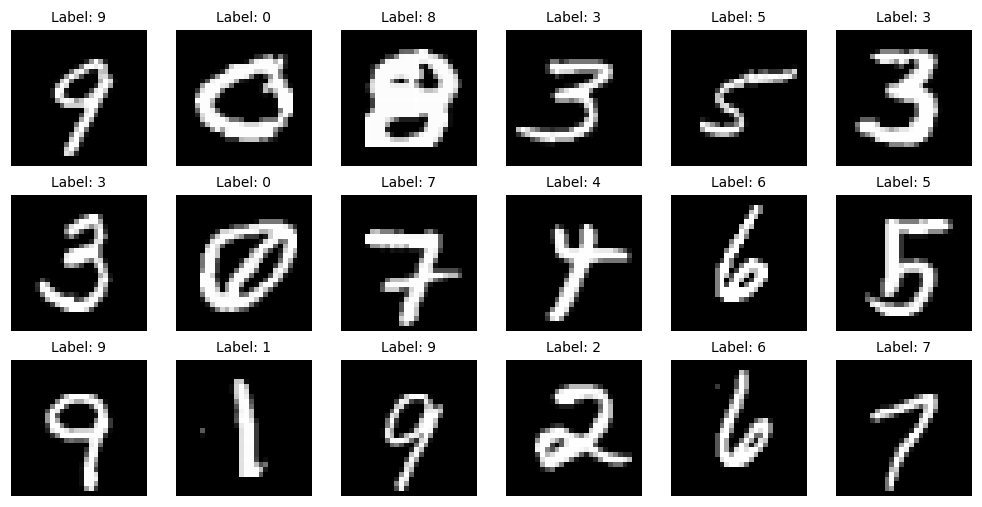

In [9]:
def make_training_loaders():
    train_loader = DataLoader(
        train_data, batch_size=CONFIG["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(CONFIG["loader_seed"]),
        num_workers=CONFIG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
    )
    val_loader = DataLoader(
        val_data, batch_size=CONFIG["evaluation_batch_size"], shuffle=False,
        num_workers=CONFIG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
    )
    return train_loader, val_loader


train_loader, val_loader = make_training_loaders()
preview_loader = DataLoader(train_data, batch_size=CONFIG["batch_size"], shuffle=False)
preview_images, preview_labels = next(iter(preview_loader))
print("一批图像形状：", tuple(preview_images.shape))
print("一批标签形状：", tuple(preview_labels.shape))
print("标签 dtype：", preview_labels.dtype)
print("每个 epoch 的训练 batch 数量：", len(train_loader))

fig_samples, axes = plt.subplots(3, 6, figsize=(9, 4.5), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    ax.imshow(preview_images[index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {preview_labels[index].item()}", fontsize=9)
    ax.axis("off")
plt.show()


**第一个检查点：**一批图像应为 `(128, 1, 28, 28)`，标签为 `(128,)`。图像显示为黑白，是因为 MNIST 本身是灰度数据。

这四个维度依次是：批量大小、通道数、高度、宽度。一个 batch 的 128 张图像并不是 128 个通道。


## 4. 搭建小型 CNN，检查每一层的形状

| 层 | 参数 | 输出形状，B 表示 batch 大小 |
|---|---|---|
| 输入 | 单通道灰度图像 | `(B, 1, 28, 28)` |
| 卷积 + ReLU | 1→16 通道，3×3，padding=1 | `(B, 16, 28, 28)` |
| 最大池化 | 2×2，stride=2 | `(B, 16, 14, 14)` |
| 卷积 + ReLU | 16→32 通道，3×3，padding=1 | `(B, 32, 14, 14)` |
| 最大池化 | 2×2，stride=2 | `(B, 32, 7, 7)` |
| 展平 | 保留 batch 维度 | `(B, 1568)` |
| 全连接 + ReLU | 1568→64 | `(B, 64)` |
| 全连接 | 64→10 | `(B, 10)` |

最后输出的是十个类别的原始分数 logits，直接交给 `CrossEntropyLoss`，模型末尾不再添加 Softmax。需要看概率时，可以在推理时单独计算 Softmax。


In [10]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)


set_seed(CONFIG["model_seed"])
model = SmallCNN().to(DEVICE)
print(model)
print("可学习参数总数：", sum(p.numel() for p in model.parameters()))

# 先用 2 张全零图像检查形状；这不是训练
shape_check = torch.zeros(2, 1, 28, 28, dtype=torch.float32, device=DEVICE)
with torch.no_grad():
    for layer in model.features:
        shape_check = layer(shape_check)
        print(type(layer).__name__, tuple(shape_check.shape))
    for layer in model.classifier:
        shape_check = layer(shape_check)
        print(type(layer).__name__, tuple(shape_check.shape))
assert shape_check.shape == (2, 10)


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
可学习参数总数： 105866
Conv2d (2, 16, 28, 28)
ReLU (2, 16, 28, 28)
MaxPool2d (2, 16, 14, 14)
Conv2d (2, 32, 14, 14)
ReLU (2, 32, 14, 14)
MaxPool2d (2, 32, 7, 7)
Flatten (2, 1568)
Linear (2, 64)
ReLU (2, 64)
Linear (2, 10)


## 5. 写训练函数和评估函数

每个训练 batch 的步骤为：取数据 → 移到设备 → 清梯度 → 前向计算 → 损失 → 反向传播 → 更新参数。

本次选用 Adam 优化器，学习率 0.001。它与上一项 SGD 共用相同的训练调用方式，具体更新规则由优化器实现。

统计平均损失时，用 `loss.item() * 当前batch样本数` 累计，再除以总样本数。因为最后一批不一定满 128 张，不能直接对各批平均损失再做简单平均。

训练指标统计各 batch 当时的预测；验证指标使用该 epoch 结束后的固定模型。训练阶段的指标因此是该轮优化过程的汇总。

`model.eval()` 改变某些层的运行模式，`torch.no_grad()` 关闭求导图记录，两者作用不同。评估阶段都使用；每轮训练开始再调用 `model.train()`。


In [11]:
criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer, epoch):
    model.train()
    loss_sum = 0.0
    correct = 0
    seen = 0

    for batch_index, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_count = labels.size(0)
        loss_sum += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += batch_count

        if batch_index % 100 == 0:
            print(f"  epoch {epoch}: batch {batch_index}/{len(loader)}, "
                  f"running loss={loss_sum / seen:.4f}", flush=True)

    return loss_sum / seen, correct / seen


def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    seen = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            logits = model(images)
            loss = criterion(logits, labels)
            batch_count = labels.size(0)
            loss_sum += loss.item() * batch_count
            correct += (logits.argmax(dim=1) == labels).sum().item()
            seen += batch_count

    return loss_sum / seen, correct / seen


print("训练、验证函数已定义。")


训练、验证函数已定义。


## 6. 训练 5 个 epoch，按验证集选择最佳模型

每轮比较验证准确率，较高者保存；准确率相同则取验证损失更低者。训练期间不读取测试准确率。

保存时复制参数张量并写入磁盘，避免保存一个会被后续更新修改的引用。这里保存的 `state_dict` 用于恢复模型权重；若需要完整断点续训，还需要额外保存优化器和随机状态。

运行本单元会从固定种子重新建立网络。每完成一轮，就保存训练历史和最佳模型信息，便于观察进度。CPU 训练比前面的螺旋实验用时更长，批次日志会持续显示进度。


In [12]:
set_seed(CONFIG["model_seed"])
model = SmallCNN().to(DEVICE)
train_loader, val_loader = make_training_loaders()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])

history = []
best_val_accuracy = -1.0
best_val_loss = float("inf")
best_epoch = 0
training_start = perf_counter()

for epoch in range(1, CONFIG["epochs"] + 1):
    epoch_start = perf_counter()
    train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, epoch)
    val_loss, val_accuracy = evaluate(model, val_loader)
    epoch_seconds = perf_counter() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "train_accuracy": train_accuracy,
        "validation_accuracy": val_accuracy,
        "epoch_seconds": epoch_seconds,
    }
    history.append(row)

    improved = (
        val_accuracy > best_val_accuracy
        or (val_accuracy == best_val_accuracy and val_loss < best_val_loss)
    )
    if improved:
        best_val_accuracy = val_accuracy
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = {name: tensor.detach().cpu().clone()
                      for name, tensor in model.state_dict().items()}
        torch.save(best_state, BEST_MODEL_PATH)
        (OUTPUT_DIR / "best_model_info.json").write_text(
            json.dumps({"epoch": best_epoch, "validation_accuracy": best_val_accuracy,
                        "validation_loss": best_val_loss, "config": CONFIG},
                       ensure_ascii=False, indent=2), encoding="utf-8"
        )

    (OUTPUT_DIR / "training_history.json").write_text(
        json.dumps(history, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"Epoch {epoch}/{CONFIG['epochs']} | "
          f"train loss={train_loss:.4f}, acc={train_accuracy:.2%} | "
          f"val loss={val_loss:.4f}, acc={val_accuracy:.2%} | "
          f"{epoch_seconds:.1f}s" + (" | saved best" if improved else ""), flush=True)

training_seconds = perf_counter() - training_start
print(f"最佳 epoch：{best_epoch}，验证准确率：{best_val_accuracy:.2%}")
print(f"训练总用时：{training_seconds:.1f} 秒")
print("最佳模型已保存：", BEST_MODEL_PATH.resolve())


  epoch 1: batch 100/430, running loss=0.9686
  epoch 1: batch 200/430, running loss=0.6264
  epoch 1: batch 300/430, running loss=0.4785
  epoch 1: batch 400/430, running loss=0.3929
Epoch 1/5 | train loss=0.3733, acc=89.17% | val loss=0.1290, acc=96.26% | 4.5s | saved best
  epoch 2: batch 100/430, running loss=0.0968
  epoch 2: batch 200/430, running loss=0.0970
  epoch 2: batch 300/430, running loss=0.0936
  epoch 2: batch 400/430, running loss=0.0877
Epoch 2/5 | train loss=0.0871, acc=97.44% | val loss=0.0788, acc=97.48% | 4.3s | saved best
  epoch 3: batch 100/430, running loss=0.0654
  epoch 3: batch 200/430, running loss=0.0639
  epoch 3: batch 300/430, running loss=0.0644
  epoch 3: batch 400/430, running loss=0.0636
Epoch 3/5 | train loss=0.0631, acc=98.08% | val loss=0.0658, acc=97.84% | 4.2s | saved best
  epoch 4: batch 100/430, running loss=0.0497
  epoch 4: batch 200/430, running loss=0.0502
  epoch 4: batch 300/430, running loss=0.0500
  epoch 4: batch 400/430, running 

## 7. 加载最佳模型，评估完整的 10,000 张测试图像

模型选择到这里已完成。载入验证集选出的最佳权重，再进行最终测试；不要用每一轮的测试准确率决定选哪个 epoch。

同时收集预测值，后面的错误样本图和混淆矩阵直接复用这些结果，不需要重新训练。最终判定使用完整测试集，而不是某一个小批量的准确率。


In [14]:
best_model = SmallCNN().to(DEVICE)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=True))
best_model.eval()

test_loader = DataLoader(
    test_data, batch_size=CONFIG["evaluation_batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
)

test_loss_sum = 0.0
test_seen = 0
true_parts = []
predicted_parts = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        logits = best_model(images)
        loss = criterion(logits, labels)
        test_loss_sum += loss.item() * labels.size(0)
        test_seen += labels.size(0)
        true_parts.append(labels.cpu().numpy())
        predicted_parts.append(logits.argmax(dim=1).cpu().numpy())

y_true = np.concatenate(true_parts)
y_pred = np.concatenate(predicted_parts)
assert test_seen == len(test_data) == 10000
assert np.array_equal(y_true, test_data.targets.numpy())
test_correct = int((y_true == y_pred).sum())
test_accuracy = test_correct / test_seen
test_loss = test_loss_sum / test_seen
target_met = bool(test_accuracy >= CONFIG["target_test_accuracy"])

print("选择模型的最佳 epoch：", best_epoch)
print(f"测试集平均损失：{test_loss:.6f}")
print(f"测试正确数：{test_correct}/{test_seen}")
print(f"测试准确率：{test_accuracy:.2%}")
print("98% 目标：", "达到" if target_met else "未达到，请先查看训练和验证曲线分析原因")


选择模型的最佳 epoch： 5
测试集平均损失：0.038012
测试正确数：9872/10000
测试准确率：98.72%
98% 目标： 达到


## 8. 查看训练曲线、混淆矩阵与错误样本

混淆矩阵的行表示真实数字，列表示预测数字；对角线是预测正确的数量。

错误样本的 `T` 表示真实标签，`P` 表示预测标签。很多错误发生在字迹模糊或相似数字之间；观察错误可以帮助理解准确率之外的表现。


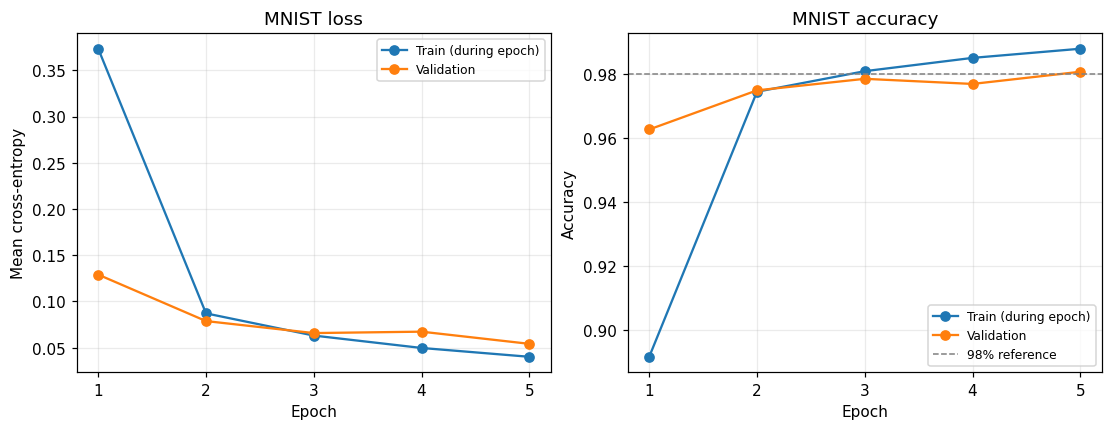

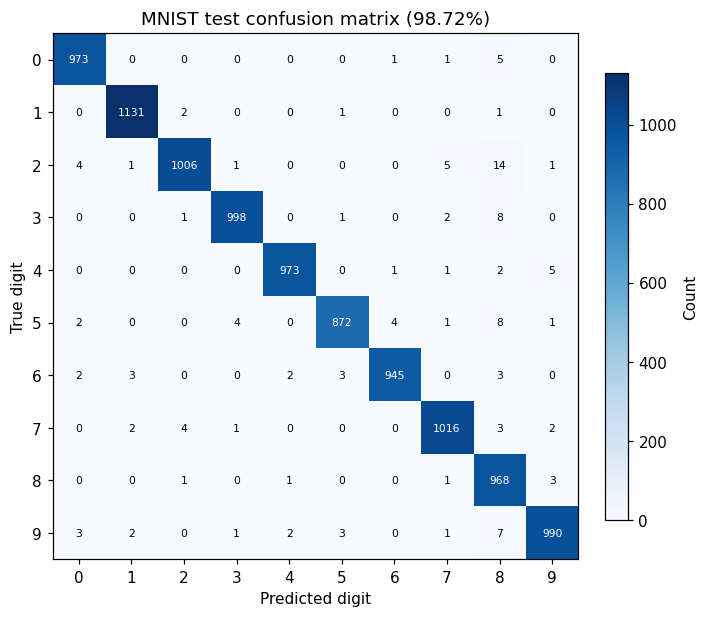

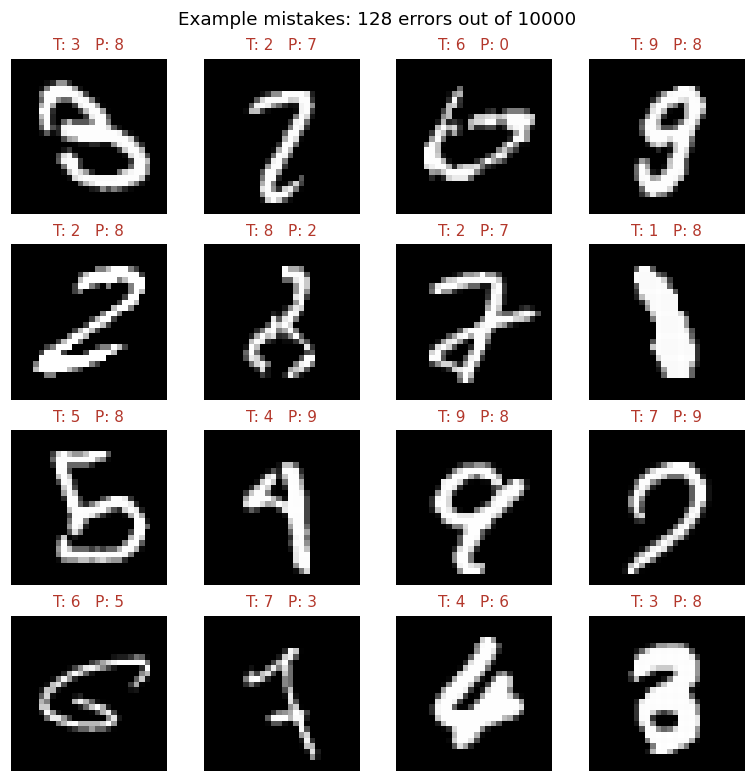

In [15]:
epochs = [row["epoch"] for row in history]
fig_curves, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].plot(epochs, [row["train_loss"] for row in history], "o-", label="Train (during epoch)")
axes[0].plot(epochs, [row["validation_loss"] for row in history], "o-", label="Validation")
axes[0].set(title="MNIST loss", xlabel="Epoch", ylabel="Mean cross-entropy", xticks=epochs)
axes[1].plot(epochs, [row["train_accuracy"] for row in history], "o-", label="Train (during epoch)")
axes[1].plot(epochs, [row["validation_accuracy"] for row in history], "o-", label="Validation")
axes[1].axhline(0.98, color="gray", linestyle="--", linewidth=1, label="98% reference")
axes[1].set(title="MNIST accuracy", xlabel="Epoch", ylabel="Accuracy", xticks=epochs)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (y_true, y_pred), 1)
fig_confusion, ax = plt.subplots(figsize=(6.4, 5.5), constrained_layout=True)
heatmap = ax.imshow(confusion, cmap="Blues")
fig_confusion.colorbar(heatmap, ax=ax, label="Count", shrink=0.85)
ax.set(title=f"MNIST test confusion matrix ({test_accuracy:.2%})",
       xlabel="Predicted digit", ylabel="True digit", xticks=range(10), yticks=range(10))
for row in range(10):
    for col in range(10):
        ax.text(col, row, str(confusion[row, col]), ha="center", va="center", fontsize=7,
                color="white" if confusion[row, col] > confusion.max() / 2 else "black")
plt.show()

wrong_indices = np.flatnonzero(y_true != y_pred)
fig_errors, axes = plt.subplots(4, 4, figsize=(7, 7), constrained_layout=True)
fig_errors.suptitle(f"Example mistakes: {len(wrong_indices)} errors out of {test_seen}")
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, wrong_indices[:16]):
    image, _ = test_data[int(index)]
    ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"T: {y_true[index]}   P: {y_pred[index]}", color="#b3372b", fontsize=10)
plt.show()


## 9. 保存图像、超参数、训练历史与测试指标

本项作业目录下的 `outputs` 会包含模型、训练历史、指标、混淆矩阵和结果图。数据集位于前面指定的独立缓存目录。

日志保存的是你这一次的实际结果，设备不同可能存在少量差异。达到要求后，应能明确报告：数据怎样划分、网络结构、优化器、学习率、batch size、训练轮数、最佳 epoch、测试正确数和准确率。


In [16]:
fig_samples.savefig(OUTPUT_DIR / "mnist_samples.png", dpi=160, bbox_inches="tight")
fig_curves.savefig(OUTPUT_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
fig_confusion.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=160, bbox_inches="tight")
fig_errors.savefig(OUTPUT_DIR / "test_mistakes.png", dpi=160, bbox_inches="tight")
np.save(OUTPUT_DIR / "test_confusion_matrix.npy", confusion)

with (OUTPUT_DIR / "training_history.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)

metrics = {
    "task": "MNIST CNN classification",
    "architecture": str(best_model),
    "parameter_count": sum(p.numel() for p in best_model.parameters()),
    "config": CONFIG,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": str(DEVICE),
    "device_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
    "cpu_threads": CPU_THREADS,
    "train_samples": len(train_data), "validation_samples": len(val_data),
    "test_samples": test_seen,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "best_validation_accuracy": best_val_accuracy,
    "test_loss": test_loss, "test_correct": test_correct,
    "test_accuracy": test_accuracy, "target_met": target_met,
    "training_seconds": training_seconds,
    "history": history,
}
(OUTPUT_DIR / "metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("已保存实验结果：", OUTPUT_DIR.resolve())
print("请按 Ctrl+S 保存 notebook 本身。")


已保存实验结果： C:\Users\ET\projects\dl-learning-journey\assignments\08_mnist_cnn\outputs
请按 Ctrl+S 保存 notebook 本身。


## 10. 完成标准与一次重点笔记

- [ ] 能说明一批图像为什么是 `(128,1,28,28)`，每一维代表什么。
- [ ] 能逐层写出卷积、池化与展平后的形状，并解释 `32*7*7=1568`。
- [ ] 能解释 DataLoader 的小批量、打乱顺序，以及一个 epoch 有多少次更新。
- [ ] 能独立说明 `zero_grad()`、`backward()`、`step()` 的分工。
- [ ] 能区分训练集、验证集和测试集，并说明最佳模型是依据什么选出的。
- [ ] 完整 10,000 张测试图像准确率达到 98%，已保存实际指标和模型。
- [ ] 已保存训练曲线、查看错误样本，并保存 notebook。

**到这里集中整理一次笔记即可。**在 Obsidian 的 `01-learning-notes` 中新建《PyTorch训练循环模板》，不需要逐节抄代码。重点写：

1. 数据流程：Dataset → DataLoader → 一个 batch → 设备 → 模型。
2. 训练流程：`model.train()` → 清梯度 → 前向与损失 → `backward()` → `step()`。
3. 验证流程：`model.eval()` + `torch.no_grad()`，累计样本数与正确数。
4. 用验证集选最佳模型，保存 `state_dict`；训练完成后再对独立测试集验收。
5. 本次自己的超参数、最佳 epoch、测试准确率及一张曲线图。

把本 notebook 第 5 节的两个函数作为你自己的训练模板，后续 U-Net 与去噪训练会沿用同一骨架，主要替换数据、网络和损失函数。

下一项按原清单进入作业 F：从零搭建一个小型 U-Net，并检查编码器、解码器和跳跃连接的形状。

官方参考：

- [Torchvision MNIST 数据接口](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html)
- [PyTorch Dataset 与 DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [PyTorch 保存与加载模型](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)
